# Making line charts in Python: Exercise solution

This is the code used to produce the exercise solution from the **Making line charts in R** script. Compare your code and output against the code and output produced here to see how well you did. Note that your code and output do not need to match the solution exactly to be considered correct!

Can you think of any other ways of making the line chart more accessible?

The line chart should:

- Show the size of the vulnerable populations of the 4 countries with the largest vulnerable populations in 2007 over the years from 1952 to 2007
-   Be formatted so that:
    -   The x-axis label is: Year 
    -   The y-axis label is: Vulnerable Population (Millions)
    -   The y-axis uses millions suffix (for example an axis break with a value of 6000000 would show as 6M)
    -   The vertical gridlines are removed
    -   The line of the country with the largest population is HEX code #1E2A16
    -   The line of the country with the second largest population is HEX code #D17E38
    -   The line of the country with the third largest population is HEX code #444443
    -   The line of the country with the fourth largest population is HEX code #3EA27F
    -   Labels with country names are at the end of lines
    -   The legend is removed
    -   The plot has confidence intervals
    -   The chart is exported as an .svg file with the file name:
        vuln_line_solution
    -   The chart is saved to the D:/exercise_outputs folder

# Setup

In [5]:
import os
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from matplotlib.pyplot import fill_between

os.chdir(r"D:\repos\analysis-for-action")

# Load the dataset
vuln = pd.read_csv("learning_resources/data/vulnerable.csv")

# Preparing the data

In [ ]:
# Filter the dataset to 2007 and display the top 6 countries with the highest vulnerable population
vuln_2007_top_4 = (
    vuln.loc[vuln["year"] == 2007].nlargest(4, "vulnerable_pop")
)

# Filter vuln dataset to just the countries named in the top 4 for 2007
vuln_top_4 = vuln.loc[vuln["country"].isin(vuln_2007_top_4["country"])]

# Create colour palette for the top 4 countries in 2007
country_colours = {
    vuln_2007_top_4.iloc[0]["country"]: "#1E2A16",
    vuln_2007_top_4.iloc[1]["country"]: "#D17E38",
    vuln_2007_top_4.iloc[2]["country"]: "#444443",
    vuln_2007_top_4.iloc[3]["country"]: "#3EA27F"
}

{'China': '#1E2A16', 'India': '#D17E38', 'United States': '#444443', 'Indonesia': '#3EA27F'}


# Creating the line chart

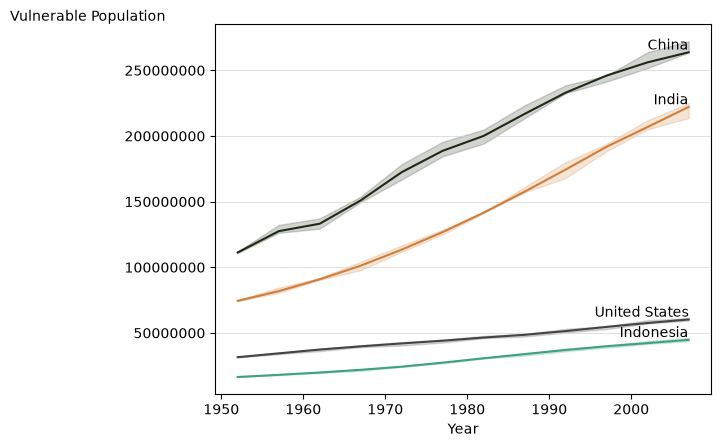

In [19]:
vuln_line_solution = sns.lineplot(
    data=vuln_top_4,
    x="year",
    y="vulnerable_pop",
    hue="country",
    palette=country_colours
)

# Add confidence intervals
for country, df_country in vuln_top_4.groupby("country"):
    fill_between(
    df_country["year"],
    df_country["lower_confidence_limit"],
    df_country["upper_confidence_limit"],
    color=country_colours[country],
    alpha=0.2
)
# Set axis titles
vuln_line_solution.set_xlabel("Year")
vuln_line_solution.set_ylabel("Vulnerable Population")
# Set the gridlines for the x-axis
vuln_line_solution.yaxis.grid(True, linestyle='-', linewidth=0.5, color='lightgrey')
# Set y-axis title to be horizontal
vuln_line_solution.yaxis.label.set_rotation(0)
vuln_line_solution.yaxis.label.set_horizontalalignment('right')
vuln_line_solution.yaxis.label.set_verticalalignment('center')
vuln_line_solution.yaxis.set_label_coords(-0.1, 1.02)
vuln_line_solution.ticklabel_format(axis='y', style='plain')
# Add labels to the end of the lines for each country
for country, df_country in vuln_top_4.groupby("country"):
    vuln_line_solution.text(
        x=df_country["year"].max(),
        y=df_country["vulnerable_pop"].iloc[-1] + 5000000,
        s=country,
        fontsize=10,
        va='center',
        ha='right'
    )
# Remove legend
vuln_line_solution.legend_.remove()

# Save the line chart as an svg file
plt.savefig("learning_resources/outputs_and_reporting/data_visualisation/basic_data_visualisation/python/exercise_outputs/vuln_line_solution.svg", format="svg")